# Function 1 - Week 4: exploration

Review the measured outputs and input coverage in the independent Week 4 `observations.csv`,
including the confirmed Week 3 return received on 14 October 2026. Continue the saved coverage shortlist.

Descriptive plots and the observed-output terrain remain here. Fitted surfaces, uncertainty,
contours and target-treatment experiments are in [model predictions](model_predictions.ipynb).


In [1]:
# Imports & shared helpers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sys

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    PLOT_CONFIG, plot_observed_terrain,
    plot_sampling_gaps,
    plot_coverage_comparison,
    plot_output_distribution,
)
from output_helpers import summarise_output_observations

# Function 1's helpers are shared across its weekly notebooks.
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_magnitudes

from function_1_model_helpers import signed_log


In [2]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [3]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_1\Week_04\observations.csv


In [4]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'y'], dtype='str')


In [5]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
y                 0
dtype: int64


In [6]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [7]:
# Splitting our data into inputs X and outputs y
output_column = "y"
input_columns = ["x1", "x2"]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [8]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [9]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 3 (1 new output).
Compared with 12 earlier observations (13 outputs in total).
Earlier output range: [-0.00550934555381, 7.7108751145e-16].

round-03: y = 1.97281177559e-200 (positive); rank 8/13 (1 = highest output).
Inputs: x1 = 0.781859, x2 = 0.025607
Within the earlier output range. Smallest non-zero magnitude so far (76.2 orders below the earlier smallest).


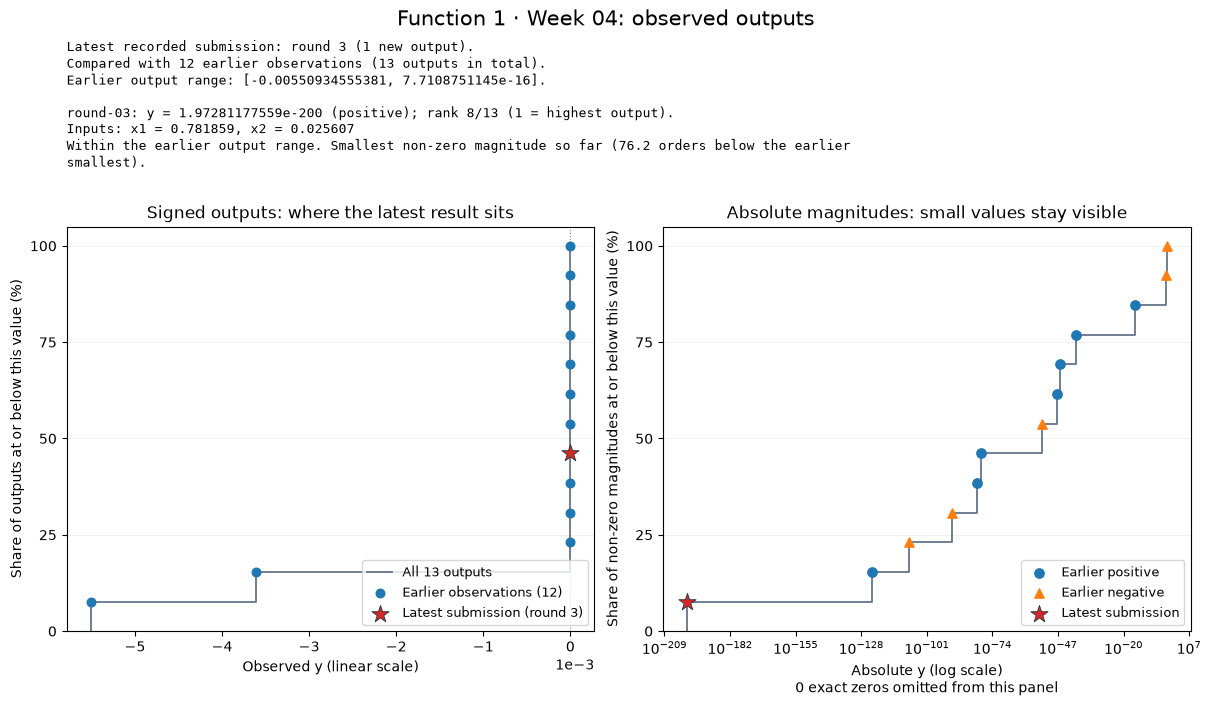

In [10]:
# Show every output, highlight the latest result and save a chart for the weekly write-up.
plot_output_distribution(
    output_review,
    title=f"{week_dir.parent.name.replace('_', ' ')} · {week_dir.name.replace('_', ' ')}: observed outputs",
    save_to=figures / "output-distribution.png",
)


Exact zeros: 0 (included on the left; omitted from the log view).
The dotted lines mark zero on the left and the near-zero boundary on the right.


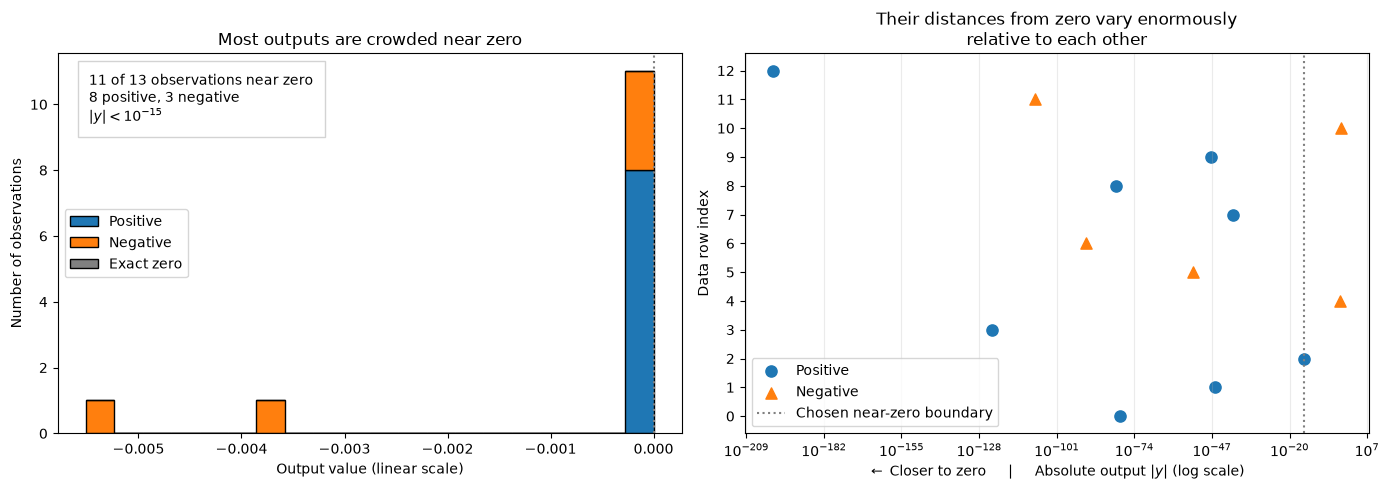

In [11]:
# Function 1 specific cell: The near-zeroness of many of the outputs is interesting
plot_output_magnitudes(y, near_zero_exponent=-15)


## Observed ranks and sampling gaps

Circle numbers are observed output ranks (1 = highest). The background shows distance to the nearest observed point. In the plan comparison, P1 and P2 identify the two remaining planned samples in submission order. These labels describe unevaluated inputs, not output ranks or predicted outputs.


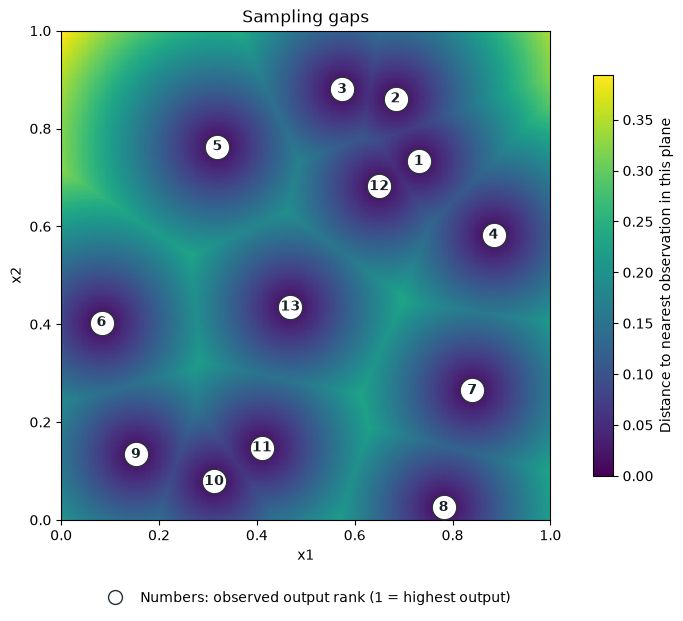

In [12]:
# Visualisation of input space coverage for query points we have so far 
plot_sampling_gaps(plot_data, save_to=figures / "sampling-gaps.png")

## Next query

The Week 3 output is **1.97281177559e-200**, ranked **8/13 (1 = highest output)**. It does not improve the best observed output, which remains **7.7108751145e-16**.

Continue with **`0.129549-0.822189`**, the next unevaluated point on [Week 2's shortlist](../Week_02/exploration.ipynb). The first two planned points are now confirmed evaluations; the saved coordinates are reused without re-optimisation. Review the updated output and sampling-gap plots before confirming the next query.


In [13]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.15308205385104573, 0.13395525138390008], [0.7818589422435338, 0.0256071460565101], [0.12954929624948736, 0.822189245547224], [0.9121401448788213, 0.8617829948823881]],
    columns=input_columns,
)

# The first two planned points were evaluated in rounds 2 and 3.
coverage_queries = planned_queries.iloc[2:].copy()
coverage_queries


,x1,x2
2,0.129549,0.822189
3,0.912140,0.861783


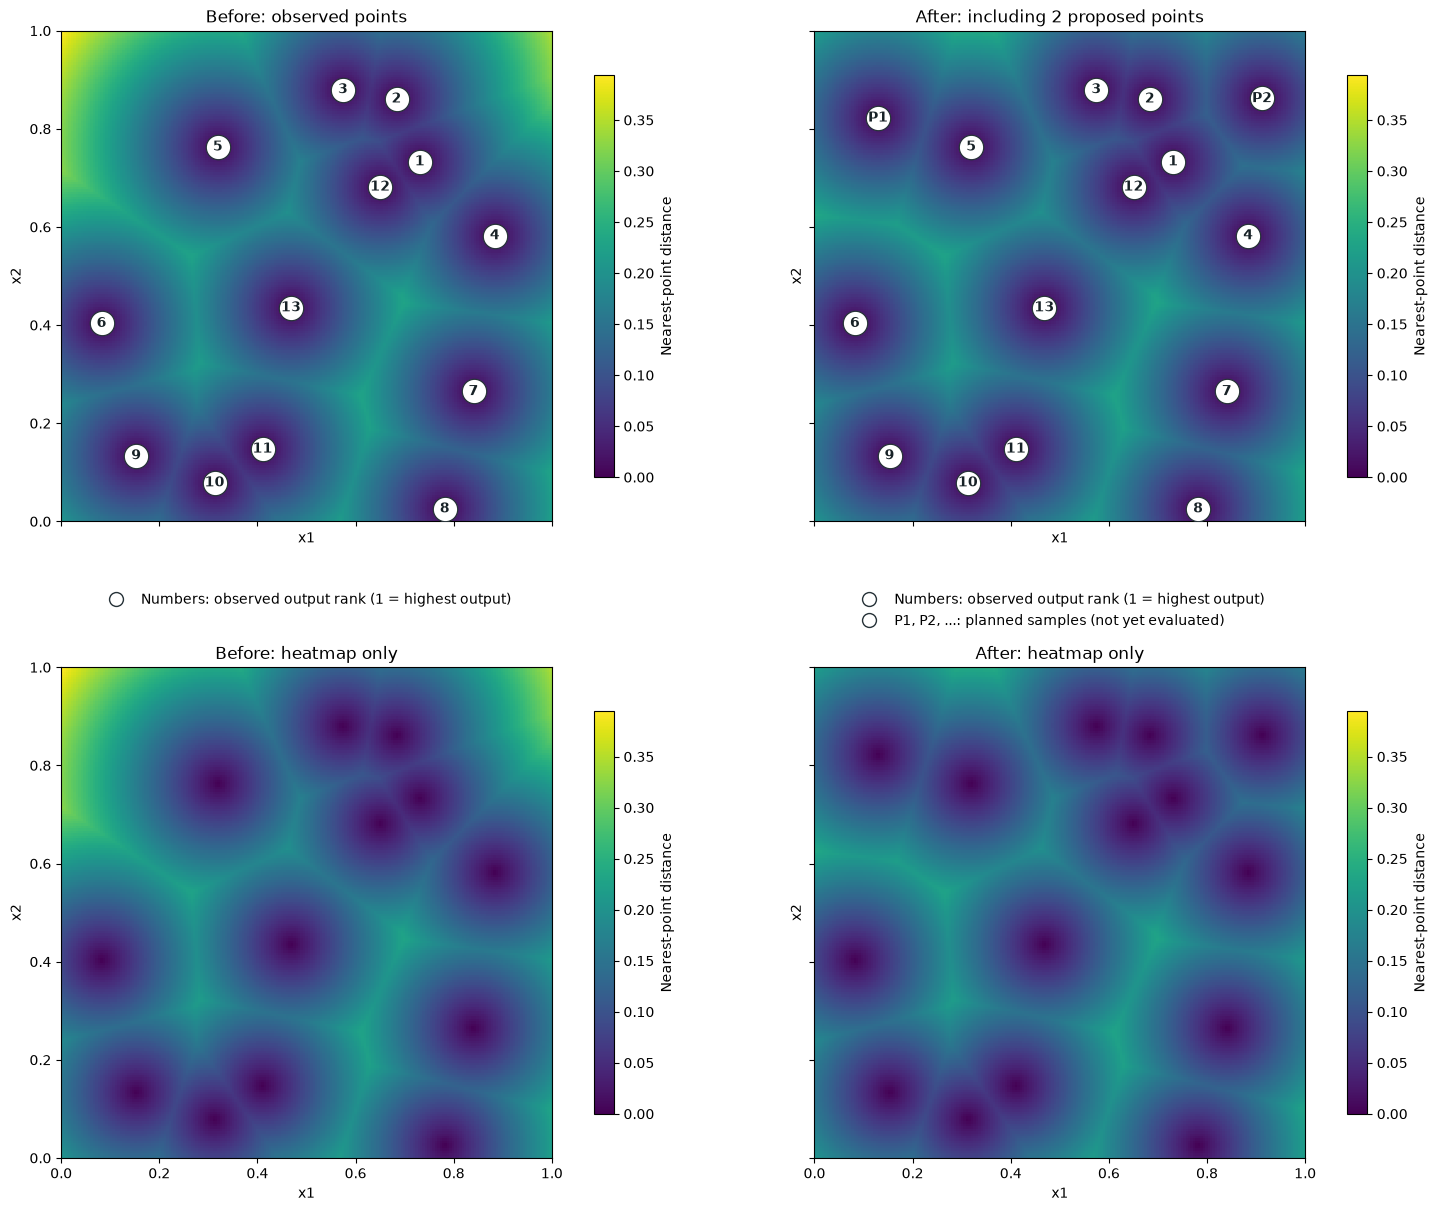

In [14]:
# Plot the remaining fixed plan against the updated observations; no search.
# None uses the before maximum; set vmax to keep a fixed scale across weeks.
plot_coverage_comparison(
    plot_data,
    coverage_queries,
    vmax=None,
    save_to=figures / "sampling-gaps-comparison.png",
)


In [15]:
# Restate the remaining submissions in their saved order.
for week, point in enumerate(coverage_queries.to_numpy(), start=4):
    portal_input = "-".join(f"{value:.6f}" for value in point)
    print(f"Week {week}: {portal_input}")


Week 4: 0.129549-0.822189
Week 5: 0.912140-0.861783


## Observed-output terrain

The signed-log height makes the enormous output range visible while preserving signs and order.
Black markers are measurements; the gold diamond identifies the highest observed output.
The triangular faces simply join measured heights. They are a visual interpolation, not a fitted regression or a known function surface.
Blank areas lie outside the sampled region. Drag to rotate, scroll to zoom, or change `terrain_relief` to adjust vertical exaggeration.


In [16]:
# Observed outputs as a draggable terrain; the display scale is Function 1-specific.
terrain_y = y.to_numpy(dtype=float)
nonzero_magnitudes = np.abs(terrain_y[terrain_y != 0])
terrain_scale = 10.0 ** np.floor(np.log10(nonzero_magnitudes.min()))
terrain_ticks = [-1e-3, 0, 1e-15]
terrain_html = figures / "observed-output-terrain.html"
terrain_fig = plot_observed_terrain(
    X.to_numpy(), terrain_y,
    title=f"Function 1: observed-output terrain ({len(terrain_y)} samples)",
    heights=signed_log(terrain_y, scale=terrain_scale),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
                     tickvals=signed_log(terrain_ticks, scale=terrain_scale),
                     ticktext=[f"{value:.0e}" if value else "0" for value in terrain_ticks]),
    height_description="signed-log heights", relief=0.16, save_to=terrain_html,
)
print(f"Height = sign(y) * log10(1 + |y| / {terrain_scale:.0e}); tick labels show original y.")
print(f"Interactive browser copy: {terrain_html}")
terrain_fig.show(config=PLOT_CONFIG)


Height = sign(y) * log10(1 + |y| / 1e-200); tick labels show original y.
Interactive browser copy: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_1\Week_04\figures\observed-output-terrain.html


## Continue with model predictions

The fitted quadratics, contour comparisons and negative-to-zero experiment are in
[model_predictions.ipynb](model_predictions.ipynb), alongside model validation and GP uncertainty plots.
That notebook loads this week's observations independently. The saved coverage sequence above remains the Week 4 query plan.
